# Case Study 3 — Predicting Titanic Survival with Logistic Regression

| | |
|---|---|
| **Subject** | Fundamentals of Data Science |
| **Course code** | 22CSC59 |
| **Faculty** | S. Durga Devi |

**Problem statement.** Given passenger records from the RMS Titanic (891 passengers, 12 attributes), build a
logistic regression model that estimates each passenger's probability of survival, evaluate it on held-out
data (accuracy, precision, recall, F1, ROC-AUC), interpret which factors drove survival, and deploy the
model as a Streamlit web app.

**Why logistic regression.** The target is binary (survived / did not survive). Logistic regression models the
*log-odds* of survival as a linear combination of features, so every coefficient has a direct meaning
("being male multiplies the odds of survival by X"). That interpretability is the point of this case study —
a black-box model could score slightly higher but could not explain *why*.

**Notebook outline**
1. Data exploration (structure, summary statistics, visualisations, statistical tests)
2. Data preprocessing (missing values, encoding, scaling — inside a leakage-safe pipeline)
3. Model building and training
4. Model evaluation (metrics, confusion matrix, ROC curve, cross-validation)
5. Interpretation (coefficients, odds ratios, statistical significance)
6. Saving the model for the Streamlit app (`app.py`)

## 0. Setup
Import the libraries used throughout. `RANDOM_STATE` is fixed so that the train/test split and every
result in this notebook is reproducible — re-running gives exactly the same numbers quoted in the report.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)
os.makedirs("model", exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data Exploration
### 1a. Load the dataset
**Purpose:** read the CSV into a DataFrame and look at the first rows to understand what each record represents.

In [2]:
df = pd.read_csv("data/titanic.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observation:** each row is one passenger. `Survived` (0 = died, 1 = survived) is the target. `PassengerId`,
`Name` and `Ticket` are identifiers rather than predictors; `Cabin` is mostly empty (see below).

### 1b. Features, data types and summary statistics
**Purpose:** confirm each column's type, count missing values, and get the central tendency / spread of the
numeric columns.

In [3]:
feature_info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
})
feature_info

,dtype,non_null,missing,missing_%,unique
PassengerId,int64,891,0,0.0,891
Survived,int64,891,0,0.0,2
Pclass,int64,891,0,0.0,3
Name,str,891,0,0.0,891
Sex,str,891,0,0.0,2
Age,float64,714,177,19.9,88
SibSp,int64,891,0,0.0,7
Parch,int64,891,0,0.0,7
Ticket,str,891,0,0.0,681
Fare,float64,891,0,0.0,248


In [4]:
df.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [5]:
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["Survived"].value_counts().rename({0: "Died (0)", 1: "Survived (1)"}))
print((df["Survived"].value_counts(normalize=True) * 100).round(2).rename({0: "Died %", 1: "Survived %"}))

Duplicate rows: 0

Target distribution:
Survived
Died (0)        549
Survived (1)    342
Name: count, dtype: int64
Survived
Died %        61.62
Survived %    38.38
Name: proportion, dtype: float64


**Observations**
- **Feature types.** Numeric: `Age`, `Fare`, `SibSp` (siblings/spouses aboard), `Parch` (parents/children aboard).
  Categorical: `Sex`, `Embarked` (port: C = Cherbourg, Q = Queenstown, S = Southampton), and `Pclass`
  (1/2/3 — stored as an integer but it is an *ordered category*, so it will be one-hot encoded).
- **Missing data.** `Cabin` 77.1% missing, `Age` 19.9% (177 rows), `Embarked` 2 rows. No duplicate rows.
- **Target balance.** 61.6% died, 38.4% survived — mildly imbalanced. A model that always predicts "died" would
  already score ~62% accuracy, so accuracy alone is a weak yardstick; precision, recall, F1 and ROC-AUC are reported too.
- **Fare is heavily right-skewed** (mean 32.2 vs median 14.45, max 512.3; skewness ≈ 4.8). A log transform will be applied.

### 1c. Visualisations
#### Missing values per column
**Purpose:** decide how to treat each column with gaps.

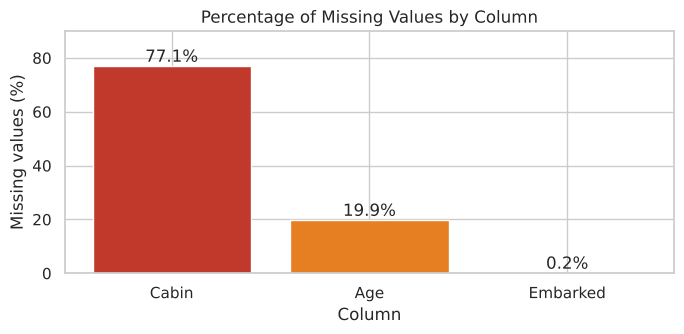

In [7]:
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(miss.index, miss.values, color=["#c0392b", "#e67e22", "#f1c40f"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set_title("Percentage of Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing values (%)")
ax.set_ylim(0, 90)
savefig("cs3_01_missing")

**Interpretation:** `Cabin` is too sparse (77%) to impute meaningfully, so the raw value is dropped — but *whether*
a cabin was recorded is itself informative (cabins were recorded mostly for 1st-class passengers), so it is kept as a
binary `HasCabin` flag. `Age` (20% missing) is imputed with the training-set median and a flag `AgeMissing` records
that it was imputed. `Embarked` (0.2%) is filled with the most frequent port.

#### Target distribution
**Purpose:** see the class balance the model must learn from.

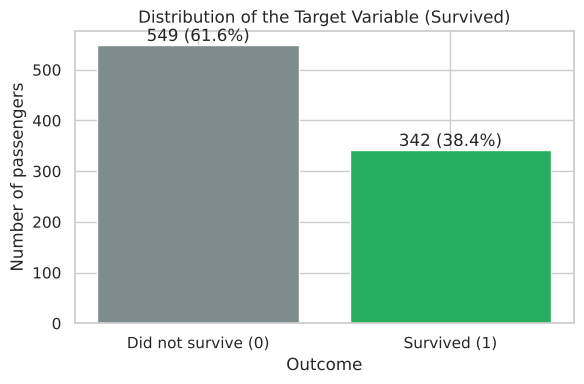

In [8]:
counts = df["Survived"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Did not survive (0)", "Survived (1)"], counts.values, color=["#7f8c8d", "#27ae60"])
ax.bar_label(bars, labels=[f"{c} ({c/len(df):.1%})" for c in counts.values])
ax.set_title("Distribution of the Target Variable (Survived)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of passengers")
savefig("cs3_02_target")

**Interpretation:** 549 passengers died and 342 survived (38.4%). The imbalance is moderate, so a stratified
train/test split is used to keep the same 62/38 ratio in both sets.

#### Survival rate by categorical features
**Purpose:** compare survival across sex, class and port of embarkation.

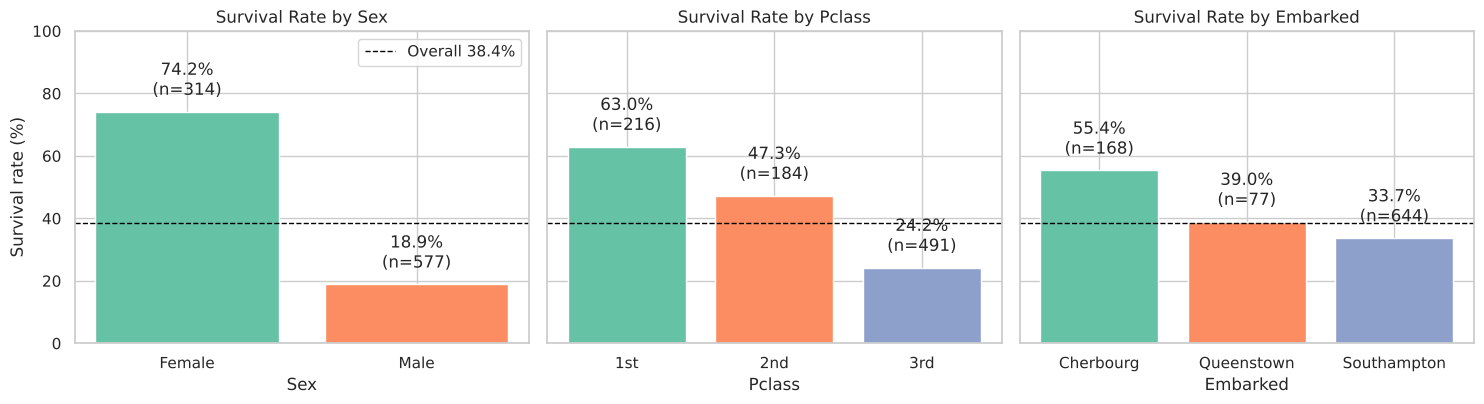

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, col, labels in zip(axes, ["Sex", "Pclass", "Embarked"],
                           [None, {1: "1st", 2: "2nd", 3: "3rd"}, {"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}]):
    rate = df.groupby(col)["Survived"].mean()
    n = df.groupby(col).size()
    names = [labels.get(i, i) if labels else str(i).title() for i in rate.index]
    bars = ax.bar(names, rate.values * 100, color=sns.color_palette("Set2", len(rate)))
    ax.bar_label(bars, labels=[f"{r:.1%}\n(n={k})" for r, k in zip(rate.values, n.values)], padding=8)
    ax.axhline(df["Survived"].mean() * 100, ls="--", c="black", lw=1, label="Overall 38.4%")
    ax.set_title(f"Survival Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Survival rate (%)")
axes[0].legend(loc="upper right")
savefig("cs3_03_survival_by_category")

**Interpretation**
- **Sex is the strongest single signal:** 74.2% of women survived versus 18.9% of men — consistent with the
  "women and children first" evacuation order.
- **Class shows a clear gradient:** 63.0% (1st) → 47.3% (2nd) → 24.2% (3rd). Higher decks were closer to the
  lifeboats and 1st-class passengers were alerted earlier.
- **Port matters less directly:** Cherbourg passengers survived at 55.4% vs 33.7% for Southampton. This is largely
  a *class* effect — a larger share of Cherbourg passengers travelled 1st class — which the multivariate model will separate out.

#### Interaction of sex and class
**Purpose:** check whether the sex effect is the same in every class.

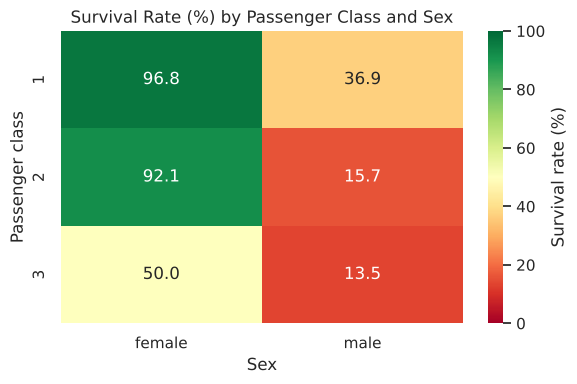

In [10]:
pivot = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=100,
            cbar_kws={"label": "Survival rate (%)"}, ax=ax)
ax.set_title("Survival Rate (%) by Passenger Class and Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Passenger class")
savefig("cs3_04_class_sex_heatmap")

**Interpretation:** 1st- and 2nd-class women survived at 96.8% and 92.1%, but 3rd-class women only at 50.0%.
Men in 2nd and 3rd class fared worst (15.7% and 13.5%). So sex and class act *together*: being female helped
everywhere, but far less so in 3rd class.

#### Distributions of the numeric features — histograms
**Purpose:** compare the shape of `Age` and `Fare` for survivors and non-survivors.

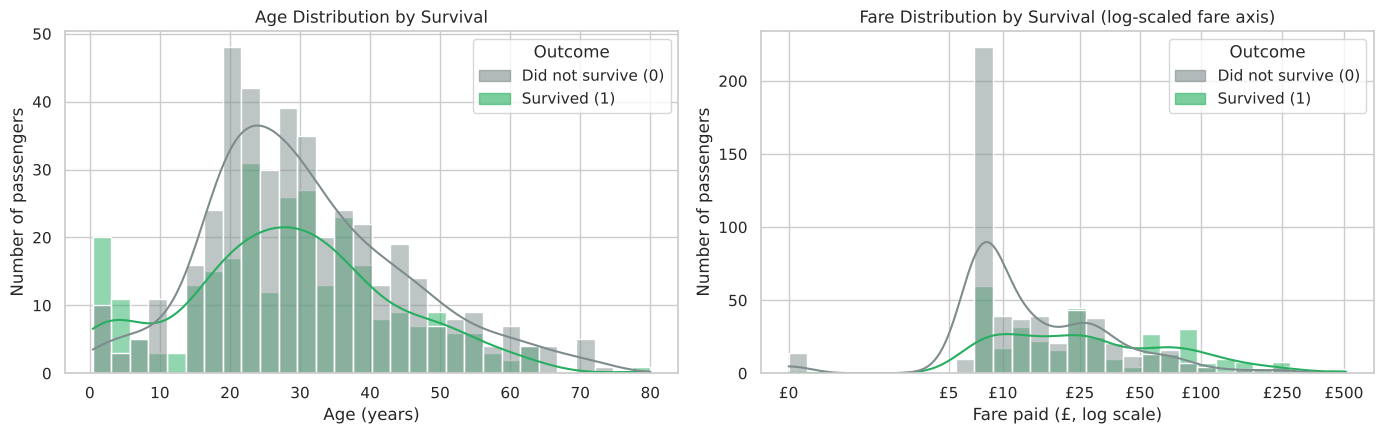

In [11]:
from matplotlib.patches import Patch
pal = {0: "#7f8c8d", 1: "#27ae60"}
handles = [Patch(color=pal[0], alpha=0.6, label="Did not survive (0)"),
           Patch(color=pal[1], alpha=0.6, label="Survived (1)")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[0],
             palette=pal, alpha=0.5, legend=False)
axes[0].set_title("Age Distribution by Survival")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")
axes[0].legend(handles=handles, title="Outcome")

tmp = df.assign(LogFare=np.log1p(df["Fare"]))
sns.histplot(data=tmp, x="LogFare", hue="Survived", bins=30, kde=True, ax=axes[1],
             palette=pal, alpha=0.5, legend=False)
ticks = [0, 5, 10, 25, 50, 100, 250, 500]
axes[1].set_xticks(np.log1p(ticks))
axes[1].set_xticklabels([f"£{t}" for t in ticks])
axes[1].set_title("Fare Distribution by Survival (log-scaled fare axis)")
axes[1].set_xlabel("Fare paid (£, log scale)")
axes[1].set_ylabel("Number of passengers")
axes[1].legend(handles=handles, title="Outcome")
savefig("cs3_05_histograms")

**Interpretation**
- **Age:** the two distributions overlap heavily, except at the youngest ages, where survivors dominate
  (children under 13 survived at 58.0% vs 36.7% for everyone else). Most passengers were 20–40.
- **Fare:** on a log scale the picture is clear — non-survivors cluster at cheap fares (about £7–£15, typical 3rd-class
  tickets), while survivors are spread towards higher fares and outnumber non-survivors above roughly £50. Raw fare has a
  long right tail (skewness 4.8, max £512), which is why `log(1 + Fare)` is used in the model (skewness drops to 0.39).

#### Box plots
**Purpose:** compare medians and spread, and spot outliers.

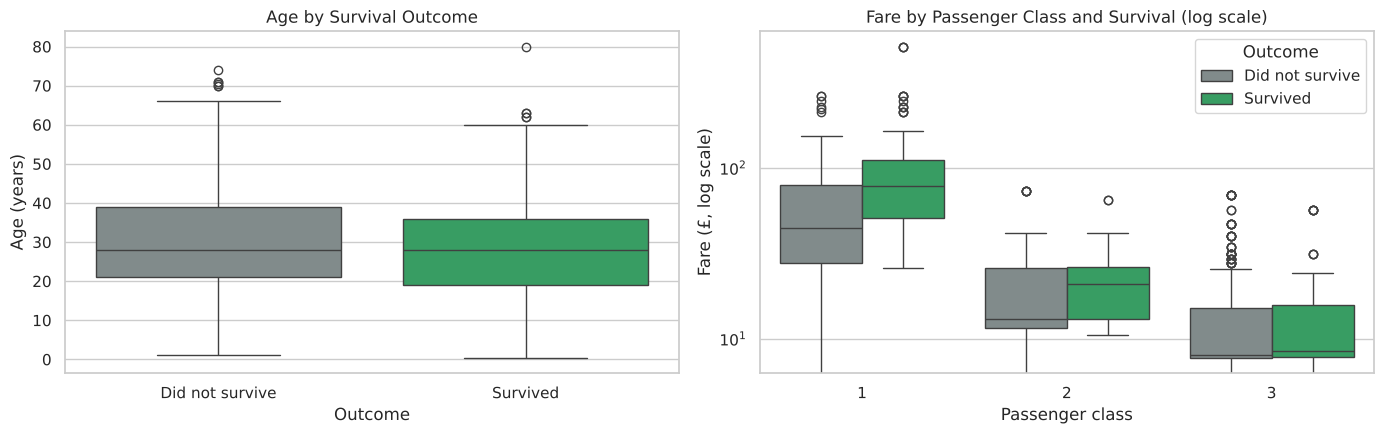

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Survived", y="Age", ax=axes[0], palette=["#7f8c8d", "#27ae60"])
axes[0].set_xticklabels(["Did not survive", "Survived"])
axes[0].set_title("Age by Survival Outcome")
axes[0].set_xlabel("Outcome")
axes[0].set_ylabel("Age (years)")

sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", ax=axes[1], palette=["#7f8c8d", "#27ae60"])
axes[1].set_yscale("log")
axes[1].set_title("Fare by Passenger Class and Survival (log scale)")
axes[1].set_xlabel("Passenger class")
axes[1].set_ylabel("Fare (£, log scale)")
h, _ = axes[1].get_legend_handles_labels()
axes[1].legend(h, ["Did not survive", "Survived"], title="Outcome")
savefig("cs3_06_boxplots")

**Interpretation**
- **Age:** median age is 28 for both groups — the box plot confirms age on its own barely separates outcomes.
- **Fare by class:** fare rises steeply with class (it is strongly tied to `Pclass`, correlation −0.55). *Within*
  1st and 2nd class, survivors' median fare is clearly higher than non-survivors' (in 3rd class the medians are almost
  equal), suggesting fare carries some information beyond class — e.g., better cabins closer to the boat deck. The many high-fare points above the whiskers are genuine luxury
  tickets, not data errors, so they are kept (the log transform tames their influence).

#### Pair plot
**Purpose:** see pairwise relationships between numeric features, coloured by outcome.

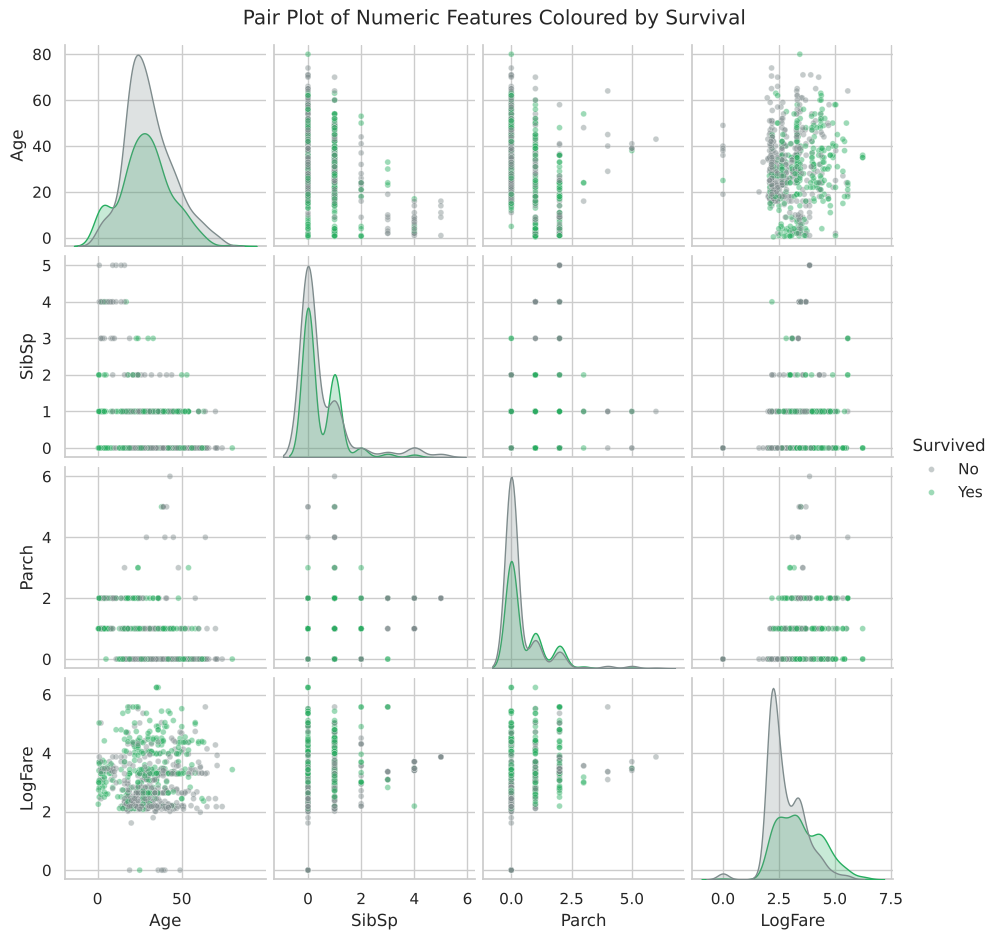

In [13]:
pp = df[["Survived", "Age", "Fare", "SibSp", "Parch"]].copy()
pp["LogFare"] = np.log1p(pp.pop("Fare"))
pp["Survived"] = pp["Survived"].map({0: "No", 1: "Yes"})
g = sns.pairplot(pp.dropna(), hue="Survived", palette={"No": "#7f8c8d", "Yes": "#27ae60"},
                 plot_kws={"alpha": 0.45, "s": 18}, diag_kind="kde", height=2.3)
g.figure.suptitle("Pair Plot of Numeric Features Coloured by Survival", y=1.02)
plt.savefig("figures/cs3_07_pairplot.png", dpi=130, bbox_inches="tight")
plt.show()

**Interpretation:** no single pair of numeric features separates survivors cleanly — the green and grey clouds
overlap — which is why the categorical features (sex, class) carry most of the signal. The clearest pattern is
along `LogFare`: survivors shift to the right. `SibSp` and `Parch` are positively related to each other (families
travel together) and very large families (SibSp ≥ 4) are almost all non-survivors.

#### Correlation heatmap
**Purpose:** quantify linear relationships between numeric/ordinal features and the target, and check for
multicollinearity before fitting a linear model.

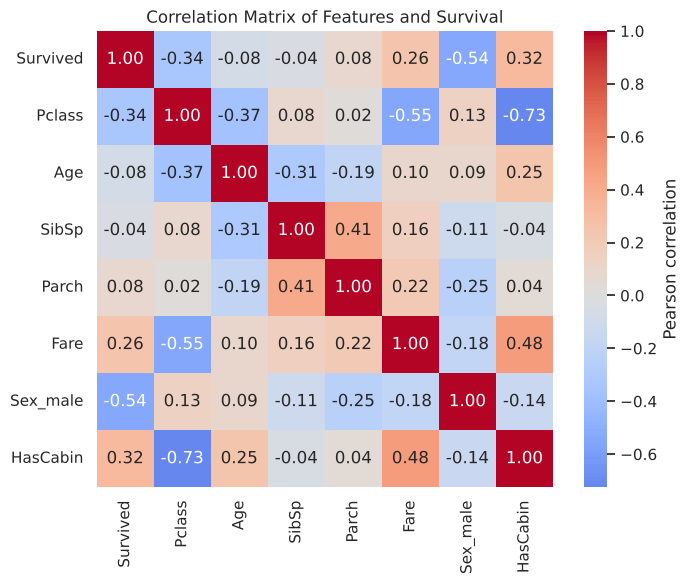

Sex_male   -0.543351
Pclass     -0.338481
Age        -0.077221
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
HasCabin    0.316912
Name: Survived, dtype: float64

In [14]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["Sex_male"] = (df["Sex"] == "male").astype(int)
corr_df["HasCabin"] = df["Cabin"].notna().astype(int)
corr = corr_df.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Matrix of Features and Survival")
savefig("cs3_08_correlation")
corr["Survived"].drop("Survived").sort_values()

**Interpretation**
- Strongest correlates of survival: `Sex_male` (−0.54), `Pclass` (−0.34), `HasCabin` (+0.32), `Fare` (+0.26).
- `Age` has almost no *linear* correlation with survival (−0.08) — but note it is correlated with `Pclass`
  (−0.37: older passengers more often in 1st class). This confounding matters and is revisited in Section 5.
- **Multicollinearity check:** the strongest predictor–predictor correlation is `Pclass`–`HasCabin` (−0.73), followed by
  `Pclass`–`Fare` (−0.55). Class, cabin and fare therefore carry overlapping information. This does not hurt prediction,
  but it makes their *individual* coefficients less certain — Section 5b shows exactly this effect.

### 1d. Statistical tests — are the patterns real or chance?
**Purpose:** the charts show differences; hypothesis tests check whether they are larger than random variation.
- **Chi-square test of independence** for categorical features vs survival (H₀: feature and survival are independent).
- **Mann–Whitney U test** for numeric features (H₀: same distribution for survivors and non-survivors). It is used
  instead of a t-test because `Fare` and `Age` are not normally distributed.

Significance level α = 0.05.

In [15]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
rows = []
for col in ["Sex", "Pclass", "Embarked", "HasCabin"]:
    table = pd.crosstab(df[col], df["Survived"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    rows.append({"Feature": col, "Test": "Chi-square", "Statistic": round(chi2, 2), "dof": dof,
                 "p-value": f"{p:.2e}", "Effect size (Cramér's V)": round(cramers_v, 3),
                 "Significant (α=0.05)": "Yes" if p < 0.05 else "No"})
for col in ["Age", "Fare"]:
    a = df.loc[df.Survived == 1, col].dropna()
    b = df.loc[df.Survived == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"Feature": col, "Test": "Mann-Whitney U", "Statistic": round(u, 1), "dof": "-",
                 "p-value": f"{p:.2e}", "Effect size (Cramér's V)": "-",
                 "Significant (α=0.05)": "Yes" if p < 0.05 else "No"})
stat_tests = pd.DataFrame(rows)
stat_tests

,Feature,Test,Statistic,dof,p-value,Effect size (Cramér's V),Significant (α=0.05)
0,Sex,Chi-square,260.72,1,1.20e-58,0.541,Yes
1,Pclass,Chi-square,102.89,2,4.55e-23,0.34,Yes
2,Embarked,Chi-square,26.49,2,1.77e-06,0.173,Yes
3,HasCabin,Chi-square,87.94,1,6.74e-21,0.314,Yes
4,Age,Mann-Whitney U,57682.00,-,1.60e-01,-,No
5,Fare,Mann-Whitney U,129951.50,-,4.55e-22,-,Yes


**Interpretation**
- `Sex` (χ² = 260.7, Cramér's V ≈ 0.54, a large effect), `Pclass` (χ² = 102.9), `HasCabin` (χ² = 87.9) and `Embarked`
  (χ² = 26.5) are all significantly associated with survival (p ≪ 0.05).
- `Fare` differs significantly between groups (median £26.0 for survivors vs £10.5 for non-survivors, p ≈ 4.6 × 10⁻²²).
- **`Age` is *not* significant on its own (p = 0.16)** — survivors and non-survivors both have a median age of 28.
  This does not mean age is irrelevant; Section 5 shows that once class is held constant, age becomes a significant
  negative factor.

## 2. Data Preprocessing
### 2a. Feature engineering and selection
**Purpose:** turn raw columns into model-ready inputs.

| Raw column | Treatment | Reason |
|---|---|---|
| `PassengerId`, `Name`, `Ticket` | dropped | identifiers with no generalisable signal |
| `Cabin` | → `HasCabin` (1/0) | 77% missing; *presence* of a cabin record is informative |
| `Age` | median imputation + `AgeMissing` flag | keeps 177 rows; flag lets the model learn if "unknown age" itself matters |
| `Fare` | → `LogFare = log(1 + Fare)` | reduces skewness from 4.8 to 0.39 so extreme fares don't dominate |
| `Embarked` | most-frequent imputation, one-hot | only 2 missing |
| `Pclass`, `Sex` | one-hot encoded (first level dropped) | categorical; dropping one level avoids perfect collinearity |
| numeric columns | standardised (mean 0, SD 1) | puts coefficients on a common per-SD scale and helps the solver converge |

In [16]:
data = df.copy()
data["HasCabin"] = data["Cabin"].notna().astype(int)
data["AgeMissing"] = data["Age"].isna().astype(int)
data["LogFare"] = np.log1p(data["Fare"])

NUM_FEATURES = ["Age", "SibSp", "Parch", "LogFare"]
CAT_FEATURES = ["Pclass", "Sex", "Embarked"]
BIN_FEATURES = ["HasCabin", "AgeMissing"]
FEATURES = NUM_FEATURES + CAT_FEATURES + BIN_FEATURES

X = data[FEATURES]
y = data["Survived"]
X.head()

,Age,SibSp,Parch,LogFare,Pclass,Sex,Embarked,HasCabin,AgeMissing
0,22.0,1,0,2.110213,3,male,S,0,0
1,38.0,1,0,4.280593,1,female,C,1,0
2,26.0,0,0,2.188856,3,female,S,0,0
3,35.0,1,0,3.990834,1,female,S,1,0
4,35.0,0,0,2.202765,3,male,S,0,0


### 2b. Train / test split
**Purpose:** hold out 20% of passengers the model never sees during training, to get an honest estimate of
performance on new data. `stratify=y` keeps the 62/38 class ratio identical in both sets.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Training set: {X_train.shape[0]} rows | survival rate {y_train.mean():.1%}")
print(f"Test set    : {X_test.shape[0]} rows | survival rate {y_test.mean():.1%}")

Training set: 712 rows | survival rate 38.3%
Test set    : 179 rows | survival rate 38.5%


### 2c. Preprocessing pipeline (missing values + encoding + scaling)
**Purpose:** wrap imputation, encoding and scaling in a scikit-learn `ColumnTransformer` inside a `Pipeline`.
This matters for correctness: the medians, most-frequent values and scaling statistics are learned **only from
the training data** and then applied to the test data, so no information leaks from the test set into training.
The same fitted pipeline is later saved and reused by the Streamlit app, so the app applies the identical transformations.

In [18]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUM_FEATURES),
    ("cat", categorical_pipe, CAT_FEATURES),
    ("bin", "passthrough", BIN_FEATURES),
])

# Check the transformed training data: no missing values should remain.
Xt = preprocessor.fit_transform(X_train)
print("Transformed shape:", Xt.shape)
print("Missing values after preprocessing:", int(np.isnan(Xt).sum()))
print("Model input columns:", list(preprocessor.get_feature_names_out()))

Transformed shape: (712, 11)
Missing values after preprocessing: 0
Model input columns: ['num__Age', 'num__SibSp', 'num__Parch', 'num__LogFare', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_male', 'cat__Embarked_Q', 'cat__Embarked_S', 'bin__HasCabin', 'bin__AgeMissing']


**Observation:** the 9 raw features become 11 model inputs (one-hot encoding expands `Pclass` and `Embarked` into two
columns each; `Sex` becomes one), and no missing values remain. Baseline (dropped) categories are
`Pclass = 1`, `Sex = female`, `Embarked = C`, so every categorical coefficient is read *relative to* those.

## 3. Model Building and Training
**Purpose:** fit a logistic regression on the training data.

Logistic regression computes
  **P(survive) = 1 / (1 + e^−(β₀ + β₁x₁ + … + βₖxₖ))**
— a weighted sum of features squashed by the sigmoid into a probability between 0 and 1. Training finds the weights β that
maximise the likelihood of the observed outcomes. scikit-learn's default L2 regularisation (`C = 1.0`) is kept: it
slightly shrinks coefficients to reduce over-fitting on this small dataset. A passenger is classified as a
survivor when P(survive) ≥ 0.5.

In [19]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
print(f"Training accuracy: {train_acc:.3f}")

Training accuracy: 0.808


### 3b. Cross-validation on the training set
**Purpose:** a single test split can be lucky or unlucky. 5-fold stratified cross-validation trains and scores the
model five times on different slices of the training data, giving a mean and spread for each metric.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_res = cross_validate(model, X_train, y_train, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
cv_table = pd.DataFrame({m: [cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std()]
                         for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
                        index=["mean", "std"]).T.round(3)
cv_table

,mean,std
accuracy,0.799,0.013
precision,0.753,0.037
recall,0.714,0.038
f1,0.732,0.015
roc_auc,0.864,0.020


## 4. Model Evaluation on the Test Set
**Purpose:** score the trained model on the 179 held-out passengers.

- **Accuracy** — share of all predictions that are correct.
- **Precision** — of the passengers predicted to survive, the share who actually survived.
- **Recall** — of the passengers who actually survived, the share the model found.
- **F1-score** — harmonic mean of precision and recall (high only if both are high).
- **ROC-AUC** — probability that the model ranks a random survivor above a random non-survivor; 0.5 = coin flip, 1.0 = perfect. Unlike the others it does not depend on the 0.5 threshold.

In [21]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Test score": [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                   recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)],
}).round(3)
baseline_acc = (y_test == 0).mean()
print(f"Baseline accuracy (always predict 'did not survive'): {baseline_acc:.3f}")
metrics

Baseline accuracy (always predict 'did not survive'): 0.615


,Metric,Test score
0,Accuracy,0.793
1,Precision,0.767
2,Recall,0.667
3,F1-score,0.713
4,ROC-AUC,0.833


In [22]:
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"], digits=3))

                 precision    recall  f1-score   support

Did not survive      0.807     0.873     0.838       110
       Survived      0.767     0.667     0.713        69

       accuracy                          0.793       179
      macro avg      0.787     0.770     0.776       179
   weighted avg      0.791     0.793     0.790       179



**Interpretation**
- **Accuracy 0.793** versus a 0.615 baseline — the model correctly classifies about 8 in 10 unseen passengers, about 18
  percentage points better than always guessing "died".
- **Precision 0.767:** when the model says "survived", it is right about 77% of the time.
- **Recall 0.667:** it finds two-thirds of actual survivors; one-third are missed (mostly passengers whose profile — e.g.
  an adult 3rd-class man — normally implies death but who survived anyway).
- **F1 0.713** balances the two. The "Did not survive" class scores higher (F1 0.838) because it is the larger, easier class.
- **ROC-AUC 0.833:** in 83% of survivor/non-survivor pairs the model gives the survivor the higher probability — good
  discrimination for a model with only 9 raw inputs.
- **Generalisation:** training accuracy (0.808) is close to test accuracy (0.793), and cross-validated scores
  (accuracy 0.799 ± 0.013, ROC-AUC 0.864 ± 0.020) agree with the test scores, so the model is not over-fitting.
  The test AUC is slightly below the CV mean — normal variation for a 179-passenger test set.

### 4b. Confusion matrix
**Purpose:** see exactly which kind of mistakes the model makes.

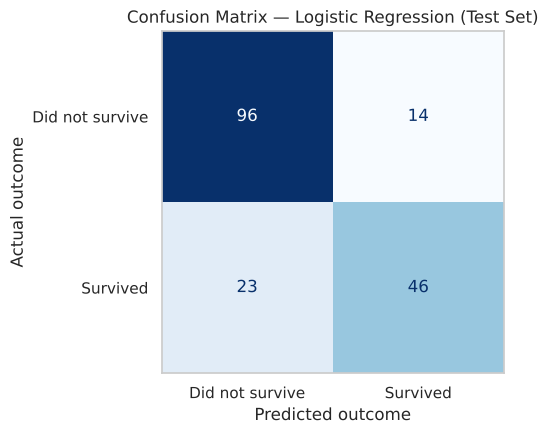

TN=96  FP=14  FN=23  TP=46


In [23]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Did not survive", "Survived"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title("Confusion Matrix — Logistic Regression (Test Set)")
ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Actual outcome")
savefig("cs3_09_confusion_matrix")
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation:** of 110 non-survivors, 96 are correctly identified and 14 are wrongly predicted to survive
(false positives). Of 69 survivors, 46 are found and 23 are missed (false negatives). The model errs more on the
side of predicting death — expected, since death is the majority class and the default 0.5 threshold favours it.
If finding survivors mattered more (higher recall), the threshold could be lowered, trading some precision.

### 4c. ROC curve
**Purpose:** show the trade-off between true-positive rate and false-positive rate at every possible threshold.

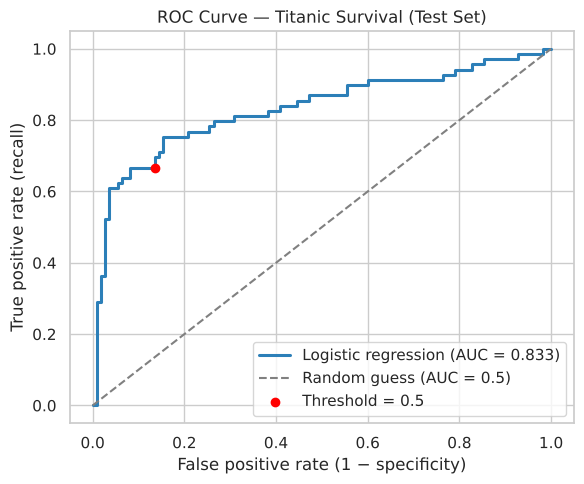

In [24]:
fpr, tpr, thr = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
i05 = np.argmin(np.abs(thr - 0.5))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color="#2c7fb8", lw=2.2, label=f"Logistic regression (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random guess (AUC = 0.5)")
ax.scatter(fpr[i05], tpr[i05], color="red", zorder=5, label="Threshold = 0.5")
ax.set_title("ROC Curve — Titanic Survival (Test Set)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
savefig("cs3_10_roc_curve")

**Interpretation:** the curve bows well above the diagonal (AUC 0.833). The red point is the default 0.5 threshold:
≈ 67% of survivors caught at a ≈ 13% false-positive rate (14 of 110 non-survivors). Moving left along the curve (higher threshold) makes
"survived" predictions more reliable; moving right catches more survivors at the cost of more false alarms.

### 4d. How the threshold changes precision and recall
**Purpose:** make the threshold trade-off concrete, since 0.5 is a default, not a law.

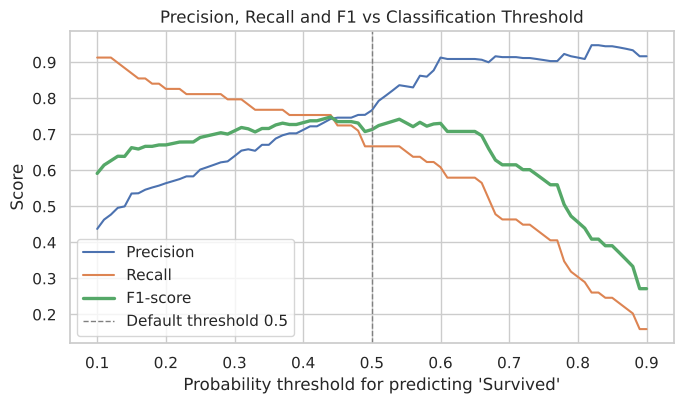

Threshold maximising F1 on the test set: 0.44 (F1 = 0.748)


In [25]:
ths = np.linspace(0.1, 0.9, 81)
prec = [precision_score(y_test, (y_prob >= t).astype(int), zero_division=0) for t in ths]
rec = [recall_score(y_test, (y_prob >= t).astype(int)) for t in ths]
f1s = [f1_score(y_test, (y_prob >= t).astype(int)) for t in ths]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ths, prec, label="Precision")
ax.plot(ths, rec, label="Recall")
ax.plot(ths, f1s, label="F1-score", lw=2.4)
ax.axvline(0.5, ls="--", c="grey", lw=1, label="Default threshold 0.5")
ax.set_title("Precision, Recall and F1 vs Classification Threshold")
ax.set_xlabel("Probability threshold for predicting 'Survived'")
ax.set_ylabel("Score")
ax.legend()
savefig("cs3_11_threshold")
best_t = ths[int(np.argmax(f1s))]
print(f"Threshold maximising F1 on the test set: {best_t:.2f} (F1 = {max(f1s):.3f})")

**Interpretation:** lowering the threshold raises recall and lowers precision; raising it does the opposite. F1 stays
within about 0.71–0.75 for any threshold between 0.30 and 0.60 (peak 0.748 at 0.44), so the model is not fragile to the
exact cut-off and the default 0.5 is a reasonable choice. The threshold is **not** re-tuned
on the test set — doing so would leak test information and inflate the reported score; this chart is diagnostic only.

## 5. Interpretation of the Model
### 5a. Coefficients and odds ratios
**Purpose:** read what the model learned. A coefficient β is the change in **log-odds** of survival for a one-unit
increase in that input (one standard deviation for numeric features; switching from the baseline category for
encoded ones). **Odds ratio = e^β**: values above 1 raise the odds of survival, below 1 lower them.

In [26]:
feat_names = [n.split("__", 1)[1] for n in model.named_steps["preprocess"].get_feature_names_out()]
coefs = model.named_steps["logreg"].coef_[0]
coef_table = pd.DataFrame({"Feature": feat_names, "Coefficient (log-odds)": coefs,
                           "Odds ratio": np.exp(coefs)}).sort_values("Coefficient (log-odds)")
print(f"Intercept: {model.named_steps['logreg'].intercept_[0]:.3f}")
coef_table.round(3).reset_index(drop=True)

Intercept: 1.399


,Feature,Coefficient (log-odds),Odds ratio
0,Sex_male,-2.486,0.083
1,Pclass_3,-0.749,0.473
2,Age,-0.488,0.614
3,Embarked_S,-0.404,0.668
4,SibSp,-0.356,0.700
5,AgeMissing,-0.221,0.802
6,Parch,-0.174,0.841
7,Pclass_2,0.147,1.158
8,Embarked_Q,0.396,1.487
9,LogFare,0.453,1.573


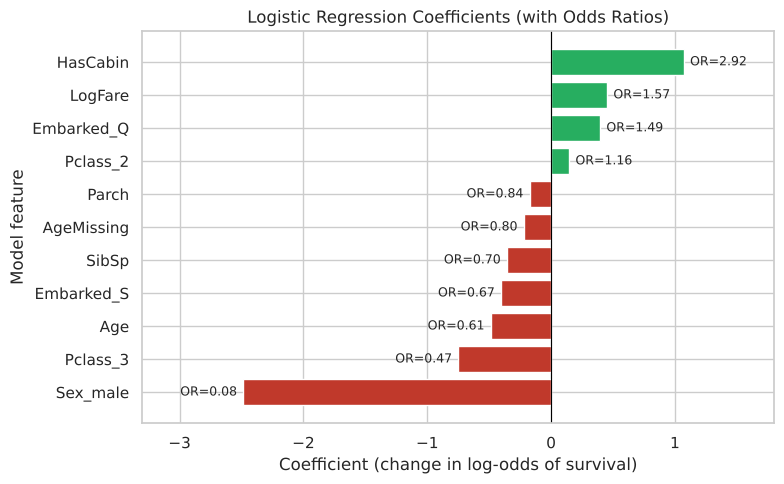

In [27]:
ct = coef_table.sort_values("Coefficient (log-odds)")
colors = ["#c0392b" if c < 0 else "#27ae60" for c in ct["Coefficient (log-odds)"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ct["Feature"], ct["Coefficient (log-odds)"], color=colors)
ax.axvline(0, color="black", lw=0.8)
for y_, (c, o) in enumerate(zip(ct["Coefficient (log-odds)"], ct["Odds ratio"])):
    ax.text(c + (0.05 if c >= 0 else -0.05), y_, f"OR={o:.2f}", va="center",
            ha="left" if c >= 0 else "right", fontsize=9)
ax.set_title("Logistic Regression Coefficients (with Odds Ratios)")
ax.set_xlabel("Coefficient (change in log-odds of survival)")
ax.set_ylabel("Model feature")
ax.set_xlim(-3.3, 1.8)
savefig("cs3_12_coefficients")

**Interpretation (holding all other features constant)**
- **Sex_male (β ≈ −2.49, OR ≈ 0.08):** being male multiplies the odds of survival by about 0.08 — roughly **12 times
  lower odds** than a comparable woman. By far the dominant factor.
- **HasCabin (OR ≈ 2.9):** passengers with a recorded cabin had about 2.9× the odds of survival — a proxy for deck
  location and status beyond what `Pclass` captures.
- **Pclass_3 (OR ≈ 0.47):** 3rd class roughly halves the odds relative to 1st class, on top of the cabin and fare effects.
  **Pclass_2** is close to 1st class once cabin and fare are accounted for. (5b shows these class estimates are individually
  uncertain because class overlaps with cabin and fare.)
- **Age (OR ≈ 0.61 per SD ≈ 13 years):** each ~13 extra years cuts the odds of survival by ~39% — older passengers fared
  worse *at the same class and sex*.
- **SibSp (OR ≈ 0.70):** more siblings/spouses aboard lowered survival — large families were harder to evacuate together.
- **LogFare (OR ≈ 1.6):** higher fare raised the odds, even within class.
- **Embarked:** relative to Cherbourg, Southampton lowers and Queenstown slightly raises the odds; these effects are small and,
  as the significance test below shows, not statistically reliable.

### 5b. Statistical significance of each feature
**Purpose:** scikit-learn does not report p-values. Re-fitting the same specification with `statsmodels` (unregularised
maximum likelihood, on the same preprocessed training data) gives standard errors, p-values and 95% confidence
intervals, so we can say which effects are statistically reliable rather than noise.

In [28]:
Xtr_t = model.named_steps["preprocess"].transform(X_train)
Xtr_sm = sm.add_constant(pd.DataFrame(Xtr_t, columns=feat_names, index=X_train.index))
logit = sm.Logit(y_train, Xtr_sm).fit(disp=0)

sig = pd.DataFrame({
    "Coef": logit.params, "Std err": logit.bse, "z": logit.tvalues, "p-value": logit.pvalues,
    "Odds ratio": np.exp(logit.params),
    "OR 95% CI low": np.exp(logit.conf_int()[0]), "OR 95% CI high": np.exp(logit.conf_int()[1]),
}).drop("const")
sig["Significant (p<0.05)"] = np.where(sig["p-value"] < 0.05, "Yes", "No")
print(f"McFadden pseudo R²: {logit.prsquared:.3f} | LLR p-value: {logit.llr_pvalue:.2e}")
sig.sort_values("p-value").round(4)

McFadden pseudo R²: 0.364 | LLR p-value: 2.53e-67


,Coef,Std err,z,p-value,Odds ratio,OR 95% CI low,OR 95% CI high,Significant (p<0.05)
Sex_male,-2.6233,0.2274,-11.5339,0.0000,0.0726,0.0465,0.1133,Yes
Age,-0.5096,0.1153,-4.4200,0.0000,0.6007,0.4792,0.7530,Yes
HasCabin,1.1582,0.3770,3.0719,0.0021,3.1842,1.5208,6.6669,Yes
SibSp,-0.3660,0.1425,-2.5682,0.0102,0.6935,0.5245,0.9170,Yes
LogFare,0.4346,0.1873,2.3198,0.0203,1.5443,1.0697,2.2294,Yes
Parch,-0.1858,0.1135,-1.6366,0.1017,0.8305,0.6648,1.0374,No
Pclass_3,-0.8187,0.5128,-1.5965,0.1104,0.4410,0.1614,1.2049,No
Embarked_S,-0.4057,0.2759,-1.4702,0.1415,0.6665,0.3881,1.1447,No
Embarked_Q,0.4707,0.4598,1.0238,0.3059,1.6011,0.6502,3.9425,No
AgeMissing,-0.2483,0.3001,-0.8271,0.4082,0.7802,0.4332,1.4049,No


**Interpretation**
- **Individually significant (p < 0.05): `Sex_male` (OR 0.07), `Age` (OR 0.60 per SD), `HasCabin` (OR 3.18), `SibSp`
  (OR 0.69) and `LogFare` (OR 1.54).** Their odds-ratio confidence intervals exclude 1, so the direction of each effect is reliable.
- **Not individually significant:** `Parch`, `Embarked_Q`, `Embarked_S`, `AgeMissing`, `Pclass_2` — and, notably, `Pclass_3`
  (p = 0.11, 95% CI for its OR 0.16–1.20). This is the multicollinearity flagged in Section 1: class, cabin and fare overlap
  (`Pclass`–`HasCabin` r = −0.73), so the model cannot cleanly attribute the effect to any one of them and each estimate
  gets a wide interval. The joint test below asks the better question — does class matter at all, given everything else?
- **Age reversal (confounding):** age was *not* significant alone (p = 0.16) but is strongly significant here (p < 0.001).
  Older passengers were more often in 1st class, which helped them; that masked the negative effect of age. Controlling
  for class reveals it — a key reason to use a multivariate model instead of one-variable comparisons.
- The likelihood-ratio test (p ≈ 2.5 × 10⁻⁶⁷) confirms the model as a whole is far better than an intercept-only model;
  McFadden pseudo-R² = 0.364 (values of 0.2–0.4 are conventionally regarded as a good fit for logistic models).

**Joint Wald test for passenger class.** H₀: both class coefficients (`Pclass_2`, `Pclass_3`) are zero.

In [29]:
wald = logit.wald_test("Pclass_2 = 0, Pclass_3 = 0", scalar=True)
print(f"Wald chi-square = {float(wald.statistic):.2f}, df = 2, p-value = {float(wald.pvalue):.4f}")

Wald chi-square = 11.22, df = 2, p-value = 0.0037


**Interpretation:** p ≈ 0.004 < 0.05, so passenger class **is** jointly significant even after controlling for cabin and
fare — class matters; its effect is simply shared with the correlated cabin and fare variables. The practical reading:
`Sex_male`, `Age`, `SibSp` and the class/cabin/fare group drive survival, while port of embarkation and number of
parents/children aboard add no reliable information.

### 5c. Worked example — what the model predicts for typical passengers
**Purpose:** translate coefficients into intuitive probabilities.

In [30]:
examples = pd.DataFrame([
    {"Age": 30, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Pclass": 1, "Sex": "female", "Embarked": "C", "HasCabin": 1},
    {"Age": 30, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Pclass": 1, "Sex": "male",   "Embarked": "C", "HasCabin": 1},
    {"Age": 25, "SibSp": 0, "Parch": 0, "Fare": 8.0,  "Pclass": 3, "Sex": "female", "Embarked": "S", "HasCabin": 0},
    {"Age": 25, "SibSp": 0, "Parch": 0, "Fare": 8.0,  "Pclass": 3, "Sex": "male",   "Embarked": "S", "HasCabin": 0},
    {"Age": 6,  "SibSp": 1, "Parch": 2, "Fare": 30.0, "Pclass": 2, "Sex": "male",   "Embarked": "S", "HasCabin": 0},
], index=["1st-class woman, 30", "1st-class man, 30", "3rd-class woman, 25", "3rd-class man, 25", "2nd-class boy, 6"])
ex = examples.copy()
ex["LogFare"] = np.log1p(ex["Fare"]); ex["AgeMissing"] = 0
examples["P(survive)"] = model.predict_proba(ex[FEATURES])[:, 1].round(3)
examples

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,HasCabin,P(survive)
"1st-class woman, 30",30,0,0,80.0,1,female,C,1,0.967
"1st-class man, 30",30,0,0,80.0,1,male,C,1,0.708
"3rd-class woman, 25",25,0,0,8.0,3,female,S,0,0.578
"3rd-class man, 25",25,0,0,8.0,3,male,S,0,0.102
"2nd-class boy, 6",6,1,2,30.0,2,male,S,0,0.322


**Interpretation**
- **Sex dominates at every ticket level:** with an identical 1st-class ticket, the woman gets 0.97 and the man 0.71; with an
  identical 3rd-class ticket, the woman gets 0.58 and the man only 0.10.
- **Class compounds it:** moving the woman from the 1st-class to the 3rd-class profile drops her probability from 0.97 to 0.58.
- **A limitation shows up too:** the 1st-class man's 0.71 is far above the 36.9% actually observed for 1st-class men. This profile
  stacks every favourable factor (cabin, high fare, Cherbourg), and because logistic regression *adds* effects in log-odds it
  cannot learn that the male penalty was harsher in practice. Similarly, the 6-year-old boy gets only 0.32: age enters
  linearly, so the model under-captures the "children first" jump for the very young (a `Child` flag or age bands would help).

## 6. Save the Trained Model for Deployment
**Purpose:** persist the complete fitted pipeline (preprocessing + logistic regression) with `joblib`. The Streamlit app
(`app.py`) loads this single file, so user inputs go through exactly the same imputation, encoding and scaling as during
training.

Run the app locally with: `streamlit run app.py`

In [31]:
joblib.dump(model, "model/titanic_logreg_pipeline.joblib")
reloaded = joblib.load("model/titanic_logreg_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X_test), model.predict_proba(X_test))
print("Saved model/titanic_logreg_pipeline.joblib — reload check passed.")

Saved model/titanic_logreg_pipeline.joblib — reload check passed.


## 7. Conclusion
- **Model performance:** logistic regression predicts Titanic survival with **79.3% accuracy, 0.767 precision, 0.667 recall,
  0.713 F1 and 0.833 ROC-AUC** on 179 unseen passengers (cross-validated AUC 0.864 ± 0.020), well above the 61.5%
  majority-class baseline, with no sign of over-fitting.
- **What determined survival:** sex was decisive (men had ~12× lower odds), followed by the class/cabin/fare group (jointly
  significant; 3rd class roughly halved the odds, a cabin record roughly tripled them), age (−39% odds per ~13 years) and number
  of siblings/spouses aboard. Port of embarkation and parents/children aboard were not statistically significant once these were
  controlled for.
- **Key analytical insight:** age looked irrelevant in isolation but was a significant negative factor after controlling for
  class — single-variable analysis can hide real effects when features are confounded.
- **Limitations:** a small dataset (891 rows); 20% of ages imputed with a single median; logistic regression assumes effects
  add linearly in log-odds, so interactions such as the much weaker benefit of being female in 3rd class are only partly
  captured; and survival depended on situational factors (location at the time of impact, lifeboat access) not in the data.
- **Deployment:** the full pipeline is saved and served through a Streamlit app (`app.py`) that returns a survival probability
  for any passenger profile.